In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/hhs_cleaned.csv', parse_dates=['Date'])
df.shape

(720, 6)

In [38]:
df = df.set_index('Date')
full_range = pd.date_range(df.index.min(), df.index.max(), freq='D')
df = df.reindex(full_range)
df.index.name = 'Date'

df_filled = df.interpolate(method='linear')
df_filled.isna().sum()  # should be 0 everywhere now

Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
dtype: int64

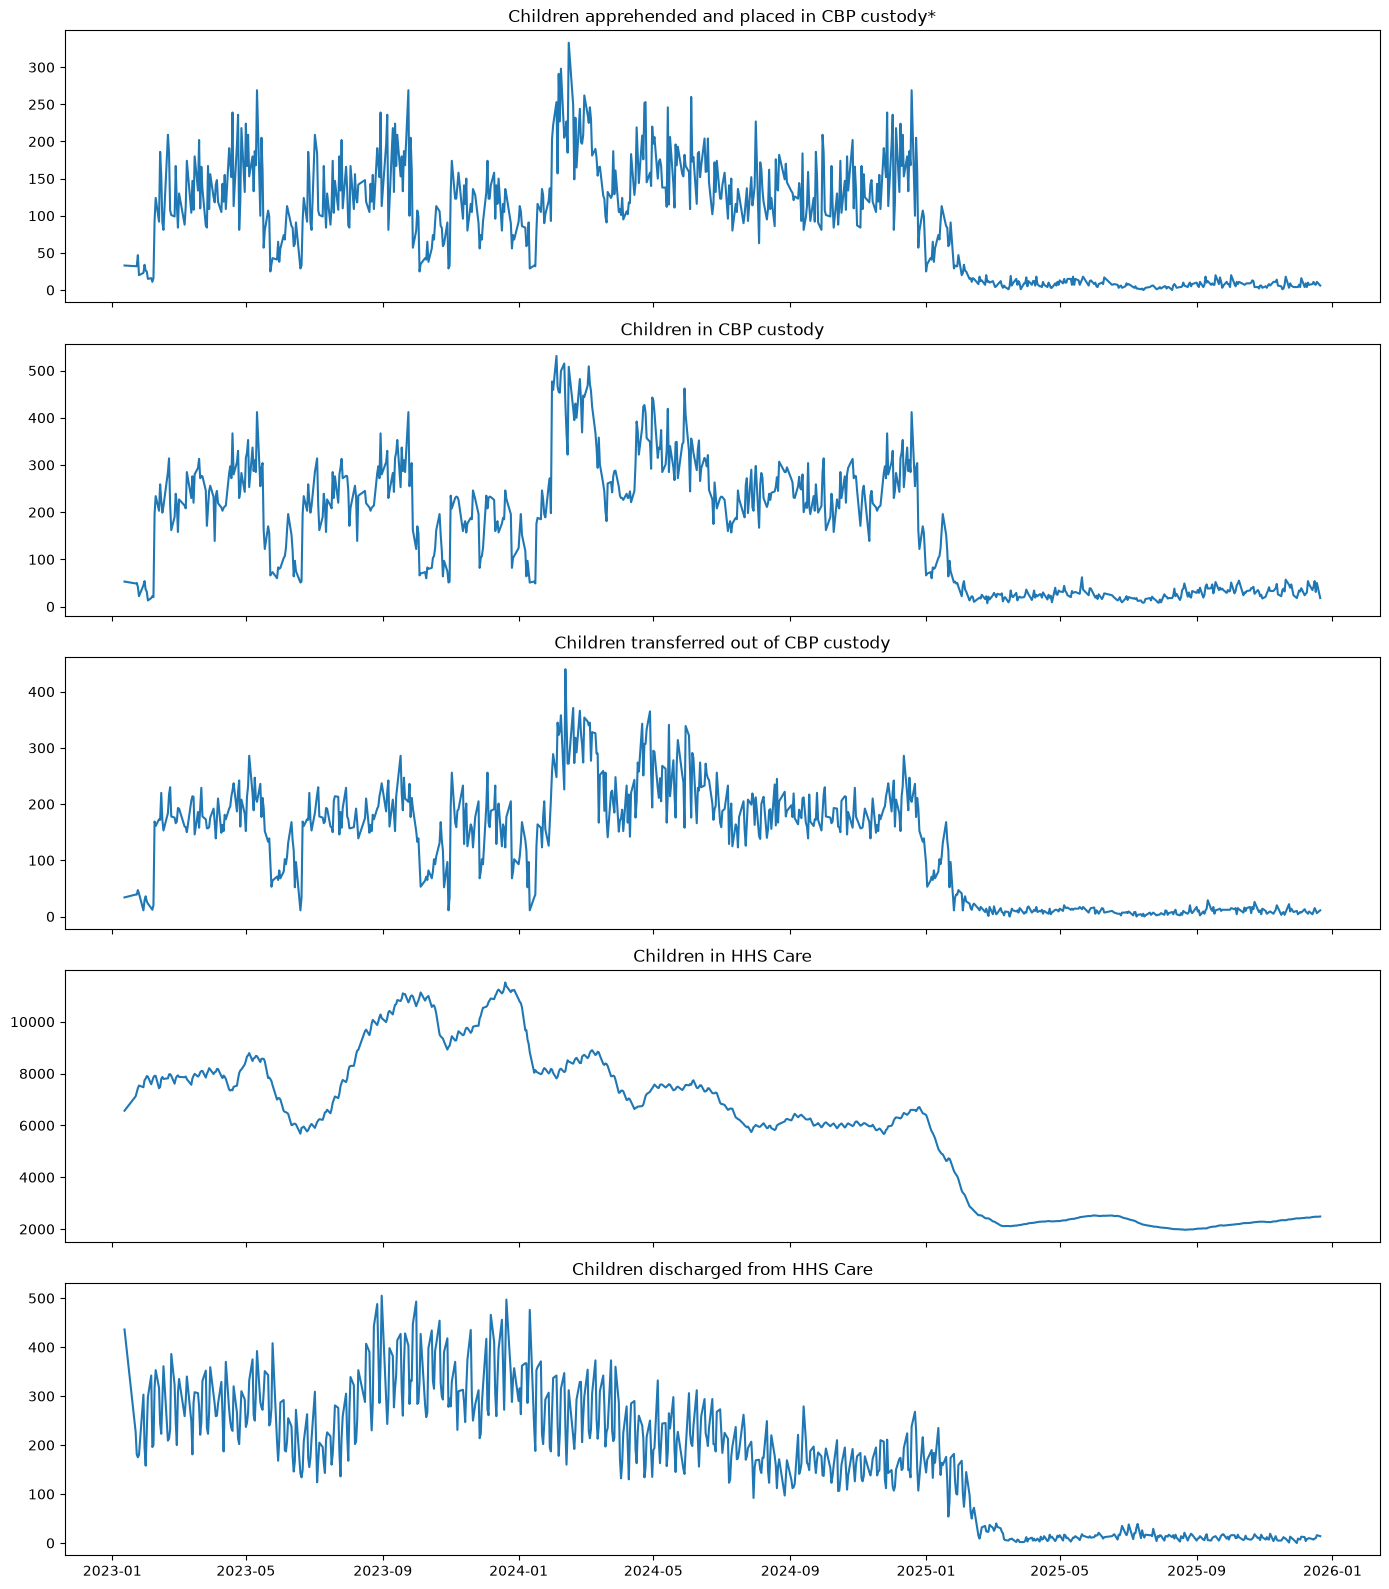

In [39]:
fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True)
for ax, col in zip(axes, df_filled.columns):
    ax.plot(df_filled.index, df_filled[col])
    ax.set_title(col)
plt.tight_layout()
plt.savefig('../outputs/figures/all_series_filled.png')
plt.show()

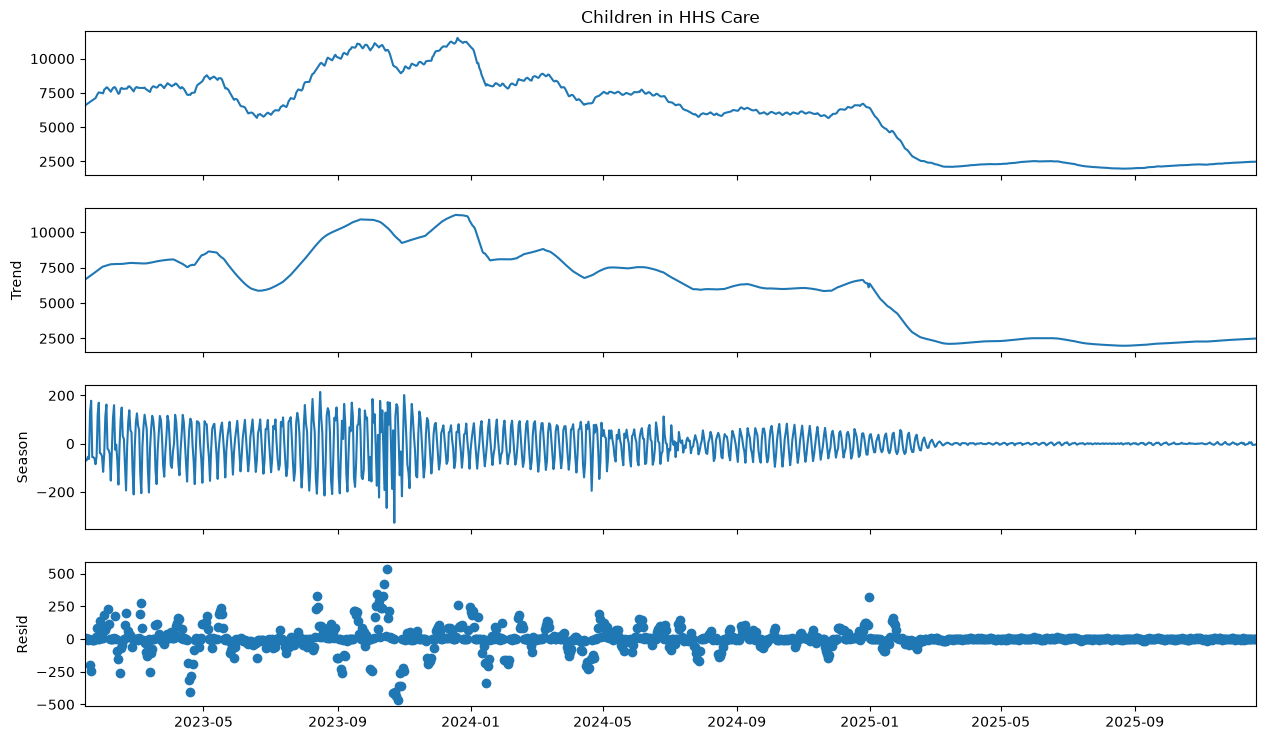

In [40]:
from statsmodels.tsa.seasonal import STL

target = 'Children in HHS Care'
stl = STL(df_filled[target], period=7, robust=True)
result = stl.fit()

fig = result.plot()
fig.set_size_inches(14, 8)
plt.savefig('../outputs/figures/stl_decomposition.png')
plt.show()

In [41]:
from statsmodels.tsa.stattools import adfuller

result_adf = adfuller(df_filled[target].dropna())
print(f"ADF Statistic: {result_adf[0]:.4f}")
print(f"p-value: {result_adf[1]:.4f}")

ADF Statistic: -1.2234
p-value: 0.6635


/tmp/ipykernel_10243/1414884739.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_adf = adfuller(df_filled[target].dropna())


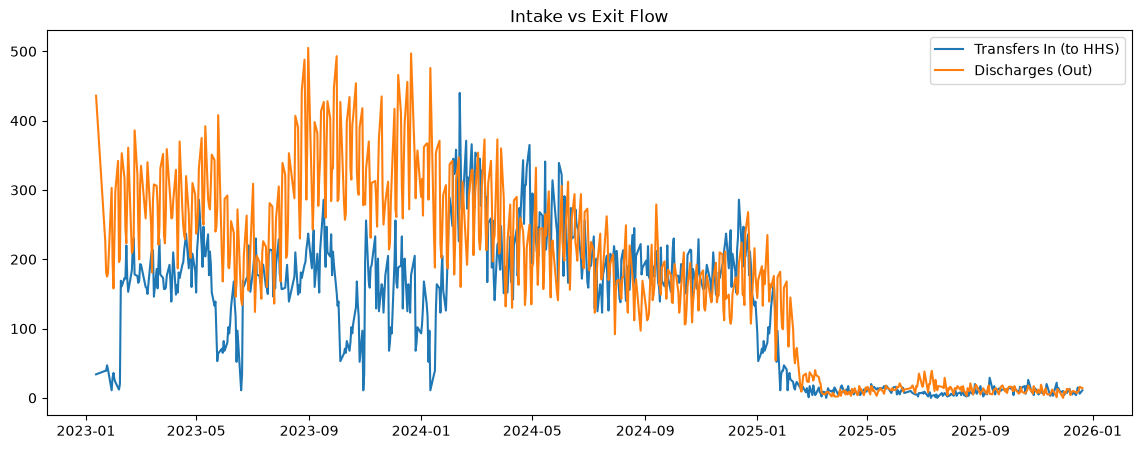

count    1075.000000
mean      -54.763256
std       100.408021
min      -465.000000
25%      -112.000000
50%       -16.000000
75%         4.000000
max       206.000000
Name: net_pressure, dtype: float64

In [42]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_filled.index, df_filled['Children transferred out of CBP custody'], label='Transfers In (to HHS)')
ax.plot(df_filled.index, df_filled['Children discharged from HHS Care'], label='Discharges (Out)')
ax.legend()
ax.set_title('Intake vs Exit Flow')
plt.savefig('../outputs/figures/flow_comparison.png')
plt.show()

df_filled['net_pressure'] = (
    df_filled['Children transferred out of CBP custody'] - df_filled['Children discharged from HHS Care']
)
df_filled['net_pressure'].describe()

In [43]:
rolling_mean = df_filled[target].rolling(14).mean()
rolling_std = df_filled[target].rolling(14).std()
z_scores = (df_filled[target] - rolling_mean) / rolling_std

anomalies = df_filled[abs(z_scores) > 3]
anomalies[[target]]

,Children in HHS Care
Date,


/tmp/ipykernel_10243/2529170021.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_d = adfuller(diff1)


ADF (1st diff): stat=-5.138, p=1.177e-05


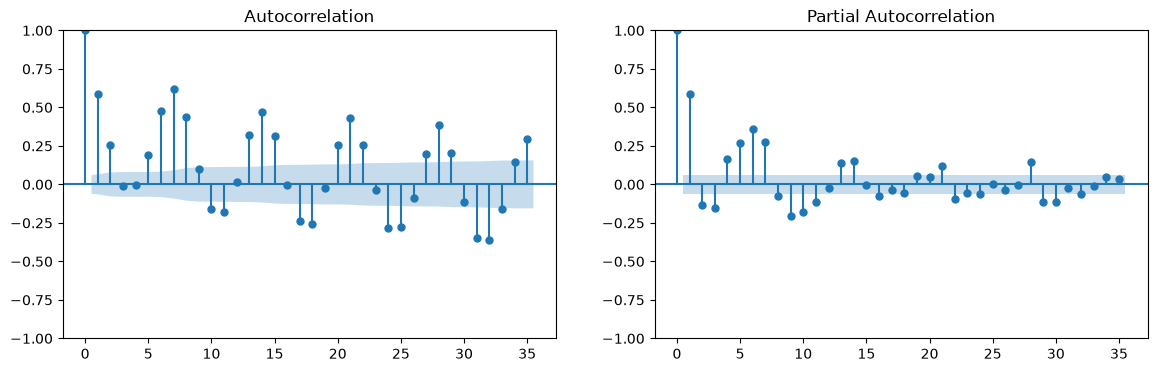

In [44]:
# 1. Stationarity on differenced series + ACF/PACF
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

diff1 = df_filled[target].diff().dropna()
adf_d = adfuller(diff1)
print(f"ADF (1st diff): stat={adf_d[0]:.3f}, p={adf_d[1]:.4g}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(diff1, lags=35, ax=ax[0])
plot_pacf(diff1, lags=35, ax=ax[1])
plt.savefig('../outputs/figures/acf_pacf_diff.png')
plt.show()


In [45]:
# 2. Day-of-week profile (observed days only, pre-break)
obs = df.dropna(subset=[target]).loc[:'2025-01-31']
cols = ['Children transferred out of CBP custody', 'Children discharged from HHS Care']
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow = obs.groupby(obs.index.day_name())[cols].mean().reindex(order).dropna().round(0)
dow

,Children transferred out of CBP custody,Children discharged from HHS Care
Date,,
Monday,172.0,218.0
Tuesday,175.0,189.0
Wednesday,182.0,227.0
Thursday,185.0,285.0
Friday,212.0,279.0
Sunday,185.0,294.0


In [46]:
# 3. Regime shift: pre vs post Feb 2025
break_date = '2025-02-01'
regime = pd.DataFrame({
    'pre':  df_filled.loc[:break_date].mean(),
    'post': df_filled.loc[break_date:].mean(),
}).round(1)
daily_chg = df_filled[target].diff().abs()
print("Median |daily change| pre/post:",
      daily_chg.loc[:break_date].median(), daily_chg.loc[break_date:].median())
regime

Median |daily change| pre/post: 57.75 6.200000000000273


,pre,post
Children apprehended and placed in CBP custody*,128.0,8.4
Children in CBP custody,230.1,26.9
Children transferred out of CBP custody,178.5,10.4
Children in HHS Care,7679.7,2302.2
Children discharged from HHS Care,254.2,16.8
net_pressure,-75.7,-6.4


In [47]:
# 4. Anomalies on daily changes (not the level)
chg = df_filled[target].diff()
z = (chg - chg.rolling(28).mean()) / chg.rolling(28).std()
anomalies = df_filled.loc[z.abs() > 3, [target]].assign(change=chg, z=z.round(1))
anomalies

,Children in HHS Care,change,z
Date,,,
2023-06-20,5904.0,225.0,3.3
2025-05-08,2361.0,26.0,3.4
2025-09-11,2047.0,22.0,3.2


In [48]:
# 5. Save the gap-filled data for later notebooks
df_filled.to_csv('../data/hhs_filled.csv')

## EDA Summary

- **Data:** 1,075 daily rows (2023-01-12 to 2025-12-21) after reindexing; 355 missing days linearly interpolated. About 85% of the gaps fall on Fridays and Saturdays, so they are a reporting pattern; the longest gap is 9 days.
- **Regime break (~Feb 2025):** all five series collapse together. Children in HHS Care averaged ~7,700 before and ~2,300 after, and has stayed within 1,972–2,528 since March 2025. Median absolute daily change fell from ~57 to ~6.
- **Peak and low:** peak 11,516 (2023-12-20); low 1,972 (2025-08-21).
- **Trend and seasonality (STL, period=7):** trend carries most of the signal. The weekly component is about ±200 early on and fades to near zero after the break. Residuals are widest in 2023 and negligible after Feb 2025.
- **Stationarity:** level is non-stationary (ADF p = 0.66); first difference is stationary (p ≈ 1e-5). ARIMA should use d = 1.
- **Flow balance:** net pressure (transfers − discharges) averages −55/day and is positive on only ~31% of days. It correlates only ~0.35 with the daily change in HHS care, so it is a weak standalone predictor.
- **Weekly pattern:** discharges run higher on Thu, Fri and Sun (~280–295) than Mon–Wed (~190–225); transfers are flatter.
- **Anomalies:** no |z| > 3 on the level series (expected for a smooth series).

**Implications for modelling:** evaluate across both regimes rather than a single end-of-series split, score on observed days only, consider modelling daily change rather than level, and treat SARIMA (s=7) as optional.